# Novelty and outlier detection with Local Outlier Factor: scikit-learn vs Moxie

**Reference examples** at scikit-learn `4358542a1bd39af2e7e1cbace8b9fed067473c5b`:
- `../scikit-learn/examples/neighbors/plot_lof_novelty_detection.py`
  ([rendered gallery page](https://scikit-learn.org/dev/auto_examples/neighbors/plot_lof_novelty_detection.html))
- `../scikit-learn/examples/neighbors/plot_lof_outlier_detection.py`
  ([rendered gallery page](https://scikit-learn.org/dev/auto_examples/neighbors/plot_lof_outlier_detection.html)), as part 2.

**Scenario:**
1. Novelty detection: `LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.1)` fitted on two
   Gaussian blobs, then `predict` on new regular and abnormal points and `decision_function` on the 500×500 plotting grid.
2. Outlier detection: `LocalOutlierFactor(n_neighbors=20, contamination=0.1).fit_predict(X)` and
   `negative_outlier_factor_` on blobs plus uniform outliers.
3. Beyond the gallery: `score_samples`, `offset_`, `n_neighbors_`, the public `kneighbors`, the novelty gating errors,
   `clone`, keyword `set_params` + refit, and the same novelty fit in Float32.

**Adaptations:**
- The `np.random.seed(42)` draws are generated by the official code in Python and shared, so both sides fit the same rows.
- Moxie returns ±1 predictions as a floating array (documented label-type adaptation in `families/neighbors/docs/estimators.md`).
- `contamination="auto"` is `None` in Moxie's typed constructor (not used here: both examples pass 0.1).
- scikit-learn raises `AttributeError` for gated methods; Moxie raises `Error` whose message starts with `AttributeError:`.

**Determinism:** both references are deterministic given the seeded data; the points are continuous, so there are no
neighbor ties. All checks are numerical parity.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("neighbors/plot_lof_novelty_detection")

## 1. scikit-learn (Python reference)

### Part 1: novelty detection (official code, smaller figure)

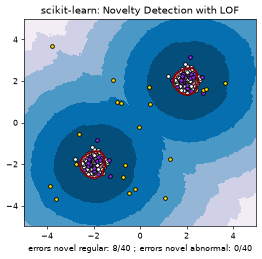

sklearn fit_predict with novelty=True: This 'LocalOutlierFactor' has no attribute 'fit_predict'


In [2]:
import matplotlib
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import numpy as np
from sklearn.neighbors import LocalOutlierFactor

np.random.seed(42)

xx, yy = np.meshgrid(np.linspace(-5, 5, 500), np.linspace(-5, 5, 500))
X = 0.3 * np.random.randn(100, 2)
X_train = np.r_[X + 2, X - 2]
X = 0.3 * np.random.randn(20, 2)
X_test = np.r_[X + 2, X - 2]
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))

clf = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.1)
clf.fit(X_train)
y_pred_test = clf.predict(X_test)
y_pred_outliers = clf.predict(X_outliers)
n_error_test = y_pred_test[y_pred_test == -1].size
n_error_outliers = y_pred_outliers[y_pred_outliers == 1].size

Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)


def draw(ax, Z, title, n_error_test, n_error_outliers):
    ax.set_title(title)
    ax.contourf(xx, yy, Z, levels=np.linspace(Z.min(), 0, 7), cmap=plt.cm.PuBu)
    ax.contour(xx, yy, Z, levels=[0], linewidths=2, colors="darkred")
    ax.contourf(xx, yy, Z, levels=[0, Z.max()], colors="palevioletred")
    s = 20
    ax.scatter(X_train[:, 0], X_train[:, 1], c="white", s=s, edgecolors="k")
    ax.scatter(X_test[:, 0], X_test[:, 1], c="blueviolet", s=s, edgecolors="k")
    ax.scatter(X_outliers[:, 0], X_outliers[:, 1], c="gold", s=s, edgecolors="k")
    ax.set(xlim=(-5, 5), ylim=(-5, 5))
    ax.set_xlabel("errors novel regular: %d/40 ; errors novel abnormal: %d/40" % (n_error_test, n_error_outliers))


fig, ax = plt.subplots(figsize=(5, 4.5), dpi=60)
draw(ax, Z, "scikit-learn: Novelty Detection with LOF", n_error_test, n_error_outliers)
plt.show()
sk_nov = dict(pred_test=y_pred_test, pred_out=y_pred_outliers, Z=Z.ravel(), offset=clf.offset_,
              score_test=clf.score_samples(X_test), nof=clf.negative_outlier_factor_, n_neighbors_=clf.n_neighbors_)
sk_kn_dist, sk_kn_ind = clf.kneighbors(X_test)
sk_self_dist, sk_self_ind = clf.kneighbors(n_neighbors=3)
X_train_nov, X_test_nov, X_outliers_nov = X_train, X_test, X_outliers
for method in ("fit_predict",):
    try:
        clf.fit_predict(X_train)
    except AttributeError as error:
        print("sklearn fit_predict with novelty=True:", error)

### Part 2: outlier detection (official code)

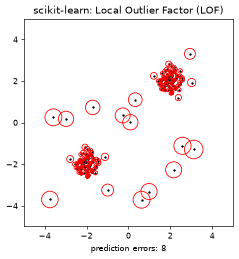

sklearn predict with novelty=False: This 'LocalOutlierFactor' has no attribute 'predict'
float32 dtypes: float32 float32


In [3]:
np.random.seed(42)

X_inliers = 0.3 * np.random.randn(100, 2)
X_inliers = np.r_[X_inliers + 2, X_inliers - 2]
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X = np.r_[X_inliers, X_outliers]

n_outliers = len(X_outliers)
ground_truth = np.ones(len(X), dtype=int)
ground_truth[-n_outliers:] = -1

clf_det = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
y_pred = clf_det.fit_predict(X)
n_errors = (y_pred != ground_truth).sum()
X_scores = clf_det.negative_outlier_factor_


def draw_scores(ax, X_scores, n_errors, title):
    ax.scatter(X[:, 0], X[:, 1], color="k", s=3.0, label="Data points")
    radius = (X_scores.max() - X_scores) / (X_scores.max() - X_scores.min())
    ax.scatter(X[:, 0], X[:, 1], s=500 * radius, edgecolors="r", facecolors="none", label="Outlier scores")
    ax.set(xlim=(-5, 5), ylim=(-5, 5), xlabel="prediction errors: %d" % n_errors, title=title)


fig, ax = plt.subplots(figsize=(4.5, 4.5), dpi=60)
draw_scores(ax, X_scores, n_errors, "scikit-learn: Local Outlier Factor (LOF)")
plt.show()
try:
    clf_det.predict(X)
except AttributeError as error:
    print("sklearn predict with novelty=False:", error)
sk_det = dict(y_pred=y_pred, scores=X_scores, offset=clf_det.offset_)

# Beyond the gallery: keyword set_params + refit, and the same novelty fit in Float32.
clf_det.set_params(n_neighbors=10, contamination=0.2)
sk_det["refit_pred"] = clf_det.fit_predict(X)
sk_det["refit_offset"] = clf_det.offset_
clf32 = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.1).fit(X_train_nov.astype(np.float32))
sk_f32 = dict(dec=clf32.decision_function(X_test_nov.astype(np.float32)), nof=clf32.negative_outlier_factor_)
print("float32 dtypes:", sk_f32["dec"].dtype, sk_f32["nof"].dtype)
nb.share(X_train=X_train_nov, X_test=X_test_nov, X_outliers=X_outliers_nov, grid=np.c_[xx.ravel(), yy.ravel()], X_all=X)

## 2. Moxie (native Mojo)

Both scenarios through `moxie.neighbors.LocalOutlierFactor`.

In [4]:
%%mojo lof
from numojo import NDArray
from moxie.base import clone
from moxie.neighbors import LocalOutlierFactor
from moxie_nb_io import load, save, save_floats, save_ints


def main() raises:
    var X_train = load("X_train")
    var X_test = load("X_test")
    var X_outliers = load("X_outliers")
    var grid = load("grid")
    var clf = LocalOutlierFactor(n_neighbors=20, novelty=True, contamination=0.1)
    _ = clf.fit(X_train)
    save("pred_test", clf.predict(X_test))
    save("pred_out", clf.predict(X_outliers))
    save("Z", clf.decision_function(grid))
    save("score_test", clf.score_samples(X_test))
    save("nof", clf.negative_outlier_factor_)
    save_floats("offset", [clf.offset_])
    save_ints("n_neighbors_", [clf.n_neighbors_])
    var kn = clf.kneighbors(X_test.copy())
    save("kn_dist", kn.distances.value())
    save_ints("kn_ind", kn.indices)
    var own = clf.kneighbors(None, 3)
    save("self_dist", own.distances.value())
    save_ints("self_ind", own.indices)
    try:
        _ = clf.fit_predict(X_train)
    except e:
        print("moxie fit_predict with novelty=True:", e)
    var fresh = clone(clf)
    print("clone is unfitted:", not fresh.__sklearn_is_fitted__(), "| original fitted:", clf.__sklearn_is_fitted__())

    var X = load("X_all")
    var det = LocalOutlierFactor(n_neighbors=20, contamination=0.1)
    save("y_pred", det.fit_predict(X))
    save("scores", det.negative_outlier_factor_)
    save_floats("det_offset", [det.offset_])
    try:
        _ = det.predict(X)
    except e:
        print("moxie predict with novelty=False:", e)
    _ = det.set_params(n_neighbors=10, contamination=0.2)
    save("refit_pred", det.fit_predict(X))
    save_floats("refit_offset", [det.offset_])

    var clf32 = LocalOutlierFactor[DType.float32](n_neighbors=20, novelty=True, contamination=0.1)
    _ = clf32.fit(load[DType.float32]("X_train"))
    save("dec32", clf32.decision_function(load[DType.float32]("X_test")))
    save("nof32", clf32.negative_outlier_factor_)

moxie fit_predict with novelty=True: AttributeError: fit_predict requires novelty=False
clone is unfitted: True | original fitted: True
moxie predict with novelty=False: AttributeError: predict requires novelty=True


## 3. Side by side and parity

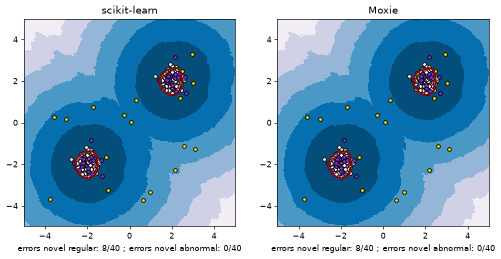

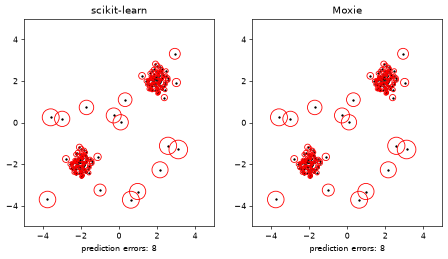

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
novelty: predict(X_test),PASS,"(40,)","(40,)",,,exact,0 mismatches,
novelty: predict(X_outliers),PASS,"(20,)","(20,)",,,exact,0 mismatches,
novelty: decision_function on 250000 grid points,PASS,"(250000,)","(250000,)",1.78e-14,5.05e-11,"rtol=1e-10, atol=1e-12",,same LOF formulas in Float64; Euclidean distances and reachability means differ only in summation order
novelty: score_samples(X_test),PASS,"(40,)","(40,)",5.55e-16,5.66e-16,"rtol=1e-10, atol=1e-12",,same LOF formulas in Float64; Euclidean distances and reachability means differ only in summation order
novelty: negative_outlier_factor_,PASS,"(200,)","(200,)",6.66e-16,6.16e-16,"rtol=1e-10, atol=1e-12",,same LOF formulas in Float64; Euclidean distances and reachability means differ only in summation order
novelty: offset_ (10th percentile),PASS,"(1,)","(1,)",2.22e-16,1.74e-16,"rtol=1e-10, atol=1e-12",,same LOF formulas in Float64; Euclidean distances and reachability means differ only in summation order
novelty: n_neighbors_,PASS,"(1,)","(1,)",,,exact,0 mismatches,
kneighbors(X_test) distances,PASS,"(40, 20)","(40, 20)",0,0,"rtol=1e-12, atol=1e-14",,Euclidean distances; summation order only
kneighbors(X_test) indices,PASS,"(40, 20)","(40, 20)",,,exact,0 mismatches,
kneighbors(n_neighbors=3) self-excluded indices,PASS,"(200, 3)","(200, 3)",,,exact,0 mismatches,


In [5]:
mx = nb.results["lof"]
n_err_test = int((mx["pred_test"] == -1).sum())
n_err_out = int((mx["pred_out"] == 1).sum())
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), dpi=60)
draw(axs[0], Z, "scikit-learn", n_error_test, n_error_outliers)
draw(axs[1], mx["Z"].reshape(xx.shape), "Moxie", n_err_test, n_err_out)
plt.show()
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5), dpi=60)
draw_scores(axs[0], sk_det["scores"], int((sk_det["y_pred"] != ground_truth).sum()), "scikit-learn")
draw_scores(axs[1], mx["scores"], int((mx["y_pred"] != ground_truth).sum()), "Moxie")
plt.show()
moxie_nb.side_by_side(sklearn=dict(errors_regular=n_error_test, errors_abnormal=n_error_outliers, offset=sk_nov["offset"]),
                      moxie=dict(errors_regular=n_err_test, errors_abnormal=n_err_out, offset=float(mx["offset"][0])))
F64 = "same LOF formulas in Float64; Euclidean distances and reachability means differ only in summation order"
nb.compare("novelty: predict(X_test)", sk_nov["pred_test"].astype(float), mx["pred_test"], exact=True)
nb.compare("novelty: predict(X_outliers)", sk_nov["pred_out"].astype(float), mx["pred_out"], exact=True)
nb.compare("novelty: decision_function on 250000 grid points", sk_nov["Z"], mx["Z"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("novelty: score_samples(X_test)", sk_nov["score_test"], mx["score_test"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("novelty: negative_outlier_factor_", sk_nov["nof"], mx["nof"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("novelty: offset_ (10th percentile)", np.array([sk_nov["offset"]]), mx["offset"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("novelty: n_neighbors_", np.array([sk_nov["n_neighbors_"]]), mx["n_neighbors_"], exact=True)
nb.compare("kneighbors(X_test) distances", sk_kn_dist, mx["kn_dist"].reshape(sk_kn_dist.shape), rtol=1e-12, atol=1e-14,
           reason="Euclidean distances; summation order only")
nb.compare("kneighbors(X_test) indices", sk_kn_ind, mx["kn_ind"].reshape(sk_kn_ind.shape), exact=True)
nb.compare("kneighbors(n_neighbors=3) self-excluded indices", sk_self_ind, mx["self_ind"].reshape(sk_self_ind.shape), exact=True)
nb.compare("kneighbors(n_neighbors=3) self-excluded distances", sk_self_dist, mx["self_dist"].reshape(sk_self_dist.shape),
           rtol=1e-12, atol=1e-14, reason="Euclidean distances; summation order only")
nb.compare("outlier detection: fit_predict(X)", sk_det["y_pred"].astype(float), mx["y_pred"], exact=True)
nb.compare("outlier detection: negative_outlier_factor_", sk_det["scores"], mx["scores"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("outlier detection: offset_", np.array([sk_det["offset"]]), mx["det_offset"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("set_params(n_neighbors=10, contamination=0.2) + fit_predict", sk_det["refit_pred"].astype(float), mx["refit_pred"], exact=True)
nb.compare("  ... offset_ after refit", np.array([sk_det["refit_offset"]]), mx["refit_offset"], rtol=1e-10, atol=1e-12, reason=F64)
nb.compare("Float32 novelty decision_function(X_test)", sk_f32["dec"], mx["dec32"], rtol=2e-5, atol=2e-6,
           reason="both sides compute in Float32 (sklearn casts distances to float32); different accumulation order "
                  "of 20-term float32 means gives a few ulps on values of order 1")
nb.compare("Float32 negative_outlier_factor_", sk_f32["nof"], mx["nof32"], rtol=2e-5, atol=2e-6, reason="as above")
nb.note("±1 labels dtype", "ADAPTED", "Moxie returns Float64 ±1 arrays (documented label adaptation); values compared exactly")
nb.note("gated methods", "ADAPTED", "Error('AttributeError: ...') instead of a Python AttributeError (docs/interfaces.md)")
nb.note("kneighbors_graph", "GAP", "sparse graph output is deferred by the family's dense scope")
nb.report()
nb.assert_parity()